# Output Verification

Development notebook for the output screening of the verification plan (`docs/validation-plan.md`). Developed one study and one metric at a time, side by side with `babelbetes/validation`.

In [1]:
import os
import sys
sys.path.append(os.path.join(os.getcwd(), '..'))

import importlib
import pandas as pd

from babelbetes import data_store, drawing
from babelbetes.validation import metrics, outliers


from matplotlib import pyplot as plt
%config InlineBackend.figure_format = 'retina'

C = dict(blue='#2a78d6', orange='#eb6834', aqua='#1baf7a', yellow='#eda100',
         magenta='#e87ba4', green='#008300', violet='#4a3aa7', red='#e34948')
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8983', '#e6e5e1'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 
    'axes.edgecolor': GRID, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.titlecolor': INK, 'axes.spines.top': False, 'axes.spines.right': False,
    'grid.color': GRID,
#    'figure.dpi': 100, 'axes.prop_cycle': plt.cycler(color=list(C.values())),
    'font.size': 10,              # base, everything relative scales from this
    'axes.labelsize': 'small',    # x/y axis labels
    'axes.titlesize': 'medium',   # replaces your 10.5 if you want it relative
    'axes.titleweight': 'bold', 
    'xtick.labelsize': 'small',   # tick numbers
    'ytick.labelsize': 'small',
    'legend.fontsize': 'small',
    'legend.title_fontsize': 'small',
    'figure.titlesize': 'medium', # plt.suptitle
})

## Load study data

In [121]:
STORE_PATH = os.path.join(os.getcwd(), '..', 'data', 'out')

store = data_store.load(STORE_PATH, 
                        data_types=['cgm', 'bolus', 'basal', 'carbs'], 
                        studies=['Flair','DCLP3','ReplaceBG', 'Loop'],
                        categorical_keys=True)

In [ ]:
df_tdd_metrics = metrics.compute(store)
display(df_tdd_metrics.sample(5))
display(df_tdd_metrics.groupby('study_name', observed=True).agg(['min','median','max']).T)

### Bivariate screen

Every metric pair is fitted jointly per study (robust lognormal, MCD). A patient is an outlier when its Mahalanobis distance exceeds `outliers.THRESHOLD`.

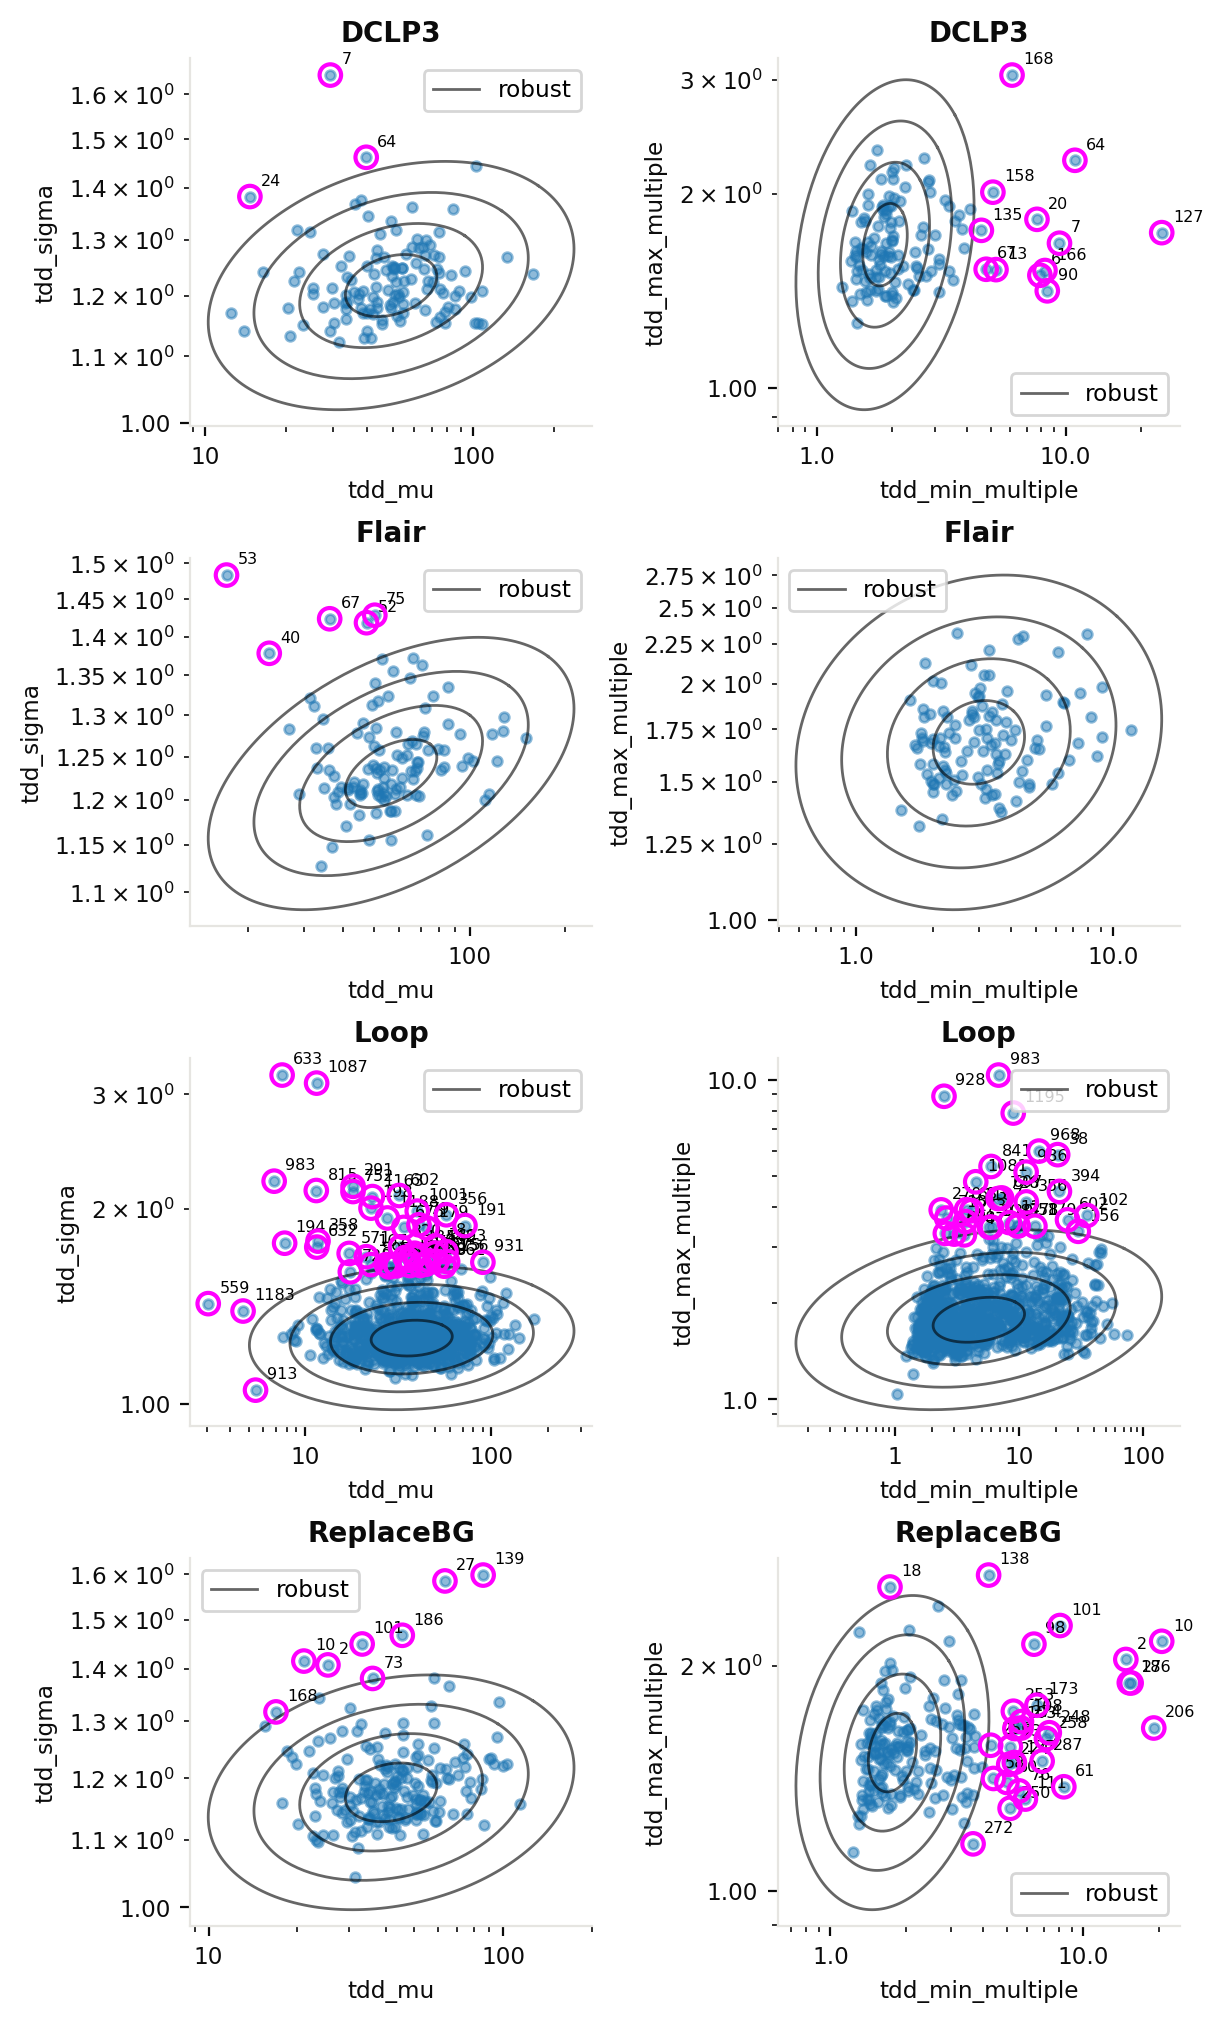

In [15]:
from babelbetes.validation import outliers
from itertools import product
from matplotlib.ticker import ScalarFormatter
importlib.reload(outliers)

THRESHOLD = 4
studies = df_tdd_metrics.index.unique('study_name')
n_rows, n_cols = len(studies), len(metrics.PAIRS)

f, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2.5 * n_rows), squeeze=False, layout='constrained')

for ax, (study, (x, y)) in zip(axes.flat, product(studies, metrics.PAIRS)):
    df = df_tdd_metrics.loc[study, [x, y]].dropna()
    mcd = outliers.fit(df, robust=True, log=True)

    ax.scatter(df[x], df[y], s=12, alpha=0.5)
    outliers.plot_confidence_ellipses(mcd, ax, linestyle='-', label='robust', n_stds=[1, 2, 3, 4], log=True, linewidth=1)
    is_outlier, _ = outliers.highlight_outliers(df, mcd, ax, edgecolors='magenta', threshold=THRESHOLD, log=True)

    for patient, row in df[is_outlier].iterrows():
        ax.annotate(patient, (row[x], row[y]), xytext=(4, 4), textcoords='offset points', fontsize='xx-small')

    ax.set(title=study, xlabel=x, ylabel=y, xscale='log', yscale='log')
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_major_formatter(ScalarFormatter())
    
    ax.legend()


## Screen (long format)

1. stack the metric pairs into one long table, one row per patient and pair
2. fit every study and pair
3. score every patient against the fit of its group
4. table of outliers and plots

### 1 · Long table

In [7]:
from babelbetes.validation import outliers
importlib.reload(outliers)

THRESHOLD = 4#outliers.THRESHOLD

pairs = []
for x, y in metrics.PAIRS:
    df = df_tdd_metrics[[x, y]].copy()
    df.columns = ['x_value', 'y_value']
    df['x'] = x
    df['y'] = y
    pairs.append(df)

df_pairs = pd.concat(pairs).set_index(['x', 'y'], append=True)
df_pairs.head()

x_value   y_value
study_name patient_id x      y                             
DCLP3      10         tdd_mu tdd_sigma  97.743412  1.197926
           100        tdd_mu tdd_sigma  42.122921  1.197248
           102        tdd_mu tdd_sigma  49.180740  1.179123
           105        tdd_mu tdd_sigma  74.945706  1.211145
           106        tdd_mu tdd_sigma  82.543316  1.235800

### 2 · Fit per study and pair

In [8]:
groups = df_pairs.groupby(['study_name', 'x', 'y'], group_keys=False)
fits = groups.apply(lambda df: outliers.fit(df, log=True, robust=True))
fits

study_name  x                 y               
DCLP3       tdd_min_multiple  tdd_max_multiple    MinCovDet(random_state=0)
            tdd_mu            tdd_sigma           MinCovDet(random_state=0)
Flair       tdd_min_multiple  tdd_max_multiple    MinCovDet(random_state=0)
            tdd_mu            tdd_sigma           MinCovDet(random_state=0)
dtype: object

### 3 · Distance to the fit of its group

In [9]:
def add_distance(df, fit):
    mask, distance = outliers.find_outliers(df[['x_value', 'y_value']], fit, threshold=THRESHOLD, log=True)
    return df.assign(outlier=mask,distance=distance)

df_distances = pd.concat([add_distance(df, fits[key]) for key, df in groups])
df_distances.groupby(['study_name', 'x', 'y']).outlier.sum()

study_name  x                 y               
DCLP3       tdd_min_multiple  tdd_max_multiple    12
            tdd_mu            tdd_sigma            3
Flair       tdd_min_multiple  tdd_max_multiple     0
            tdd_mu            tdd_sigma            5
Name: outlier, dtype: int64

### 4 · Outliers

In [10]:
df_distances.groupby(['study_name','x','y']).outlier.sum()

study_name  x                 y               
DCLP3       tdd_min_multiple  tdd_max_multiple    12
            tdd_mu            tdd_sigma            3
Flair       tdd_min_multiple  tdd_max_multiple     0
            tdd_mu            tdd_sigma            5
Name: outlier, dtype: int64

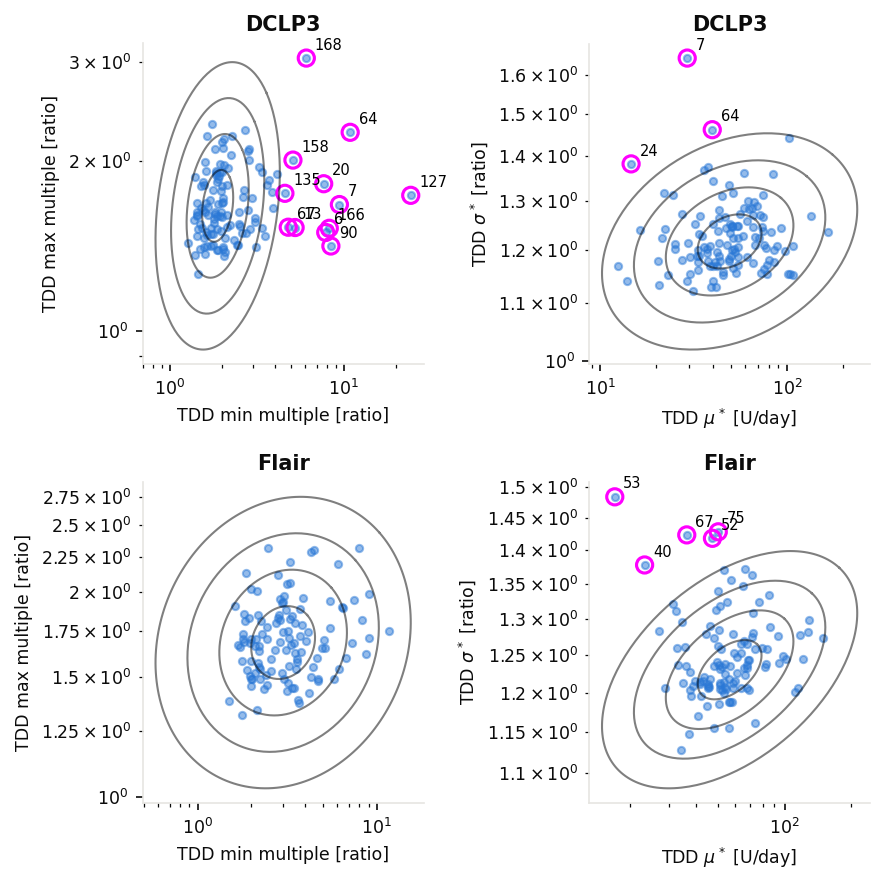

In [ ]:
label = lambda m: f"{metrics.METRICS[m]['description']} [{metrics.METRICS[m]['unit']}]"
from importlib import reload
reload(metrics)

f, AX = plt.subplots(len(fits) // len(metrics.PAIRS), len(metrics.PAIRS),
                     figsize=(3 * len(metrics.PAIRS), 3 * len(fits) // len(metrics.PAIRS)), squeeze=False)

for ax, ((study, x, y), fit) in zip(AX.flat, fits.items()):
    df = df_distances.xs((study, x, y), level=['study_name', 'x', 'y'])
    outlier = df.query('outlier')

    ax.scatter(df.x_value, df.y_value, s=12, alpha=0.5)
    
    outliers.plot_confidence_ellipses(fit, ax, log=True, color='black', linestyle='-', n_stds=[1,2,3,4],linewidth=1,alpha=0.5)
    ax.scatter(outlier.x_value, outlier.y_value, s=60, facecolors='none', edgecolors='magenta', linewidths=1.5)
    for patient, point in outlier.iterrows():
        ax.annotate(patient, (point.x_value, point.y_value), xytext=(4, 4), textcoords='offset points', fontsize=7)
    ax.set(xlabel=label(x), ylabel=label(y), title=f'{study}',xscale='log', yscale='log')
f.tight_layout()

## New

In [19]:
import numpy as np
KEYS = ['study_name','patient_id']
MANDATORY_STREAMS = ['bolus', 'basal', 'cgm']
OPTIONAL_STREAMS = ['carbs']
EXCLUDED_STREAMS = {'IOBP2': ['basal']}   # study -> streams that don't count as mandatory there

# one row per patient, stream and day with data
frames = []
for stream in MANDATORY_STREAMS + OPTIONAL_STREAMS:
    if stream not in store or store[stream].empty:
        continue
    df = store[stream]
    days = df[KEYS].assign(date=df.datetime.dt.normalize(), stream=stream)
    frames.append(days.drop_duplicates())
df_days = pd.concat(frames, ignore_index=True)
df_days
# df_days.loc[df_days.index[3],'stream'] = 'carbs'
# df_days.loc[df_days.index[6],'stream'] = 'TEST'
# df_days.head(10)

,study_name,patient_id,date,stream
0,DCLP3,10,2018-04-04,bolus
1,DCLP3,10,2018-04-05,bolus
2,DCLP3,10,2018-04-06,bolus
3,DCLP3,10,2018-04-07,bolus
4,DCLP3,10,2018-04-08,bolus
...,...,...,...,...
1428394,ReplaceBG,98,2015-09-13,carbs
1428395,ReplaceBG,98,2015-09-14,carbs
1428396,ReplaceBG,98,2015-09-15,carbs
1428397,ReplaceBG,98,2015-09-16,carbs


In [20]:
def core_window(df):
    edges = df.groupby('stream').date.agg(['min', 'max'])
    return edges['min'].max(), edges['max'].min()

def complete_days(df, n_streams):
    streams_per_day = df.groupby('date').stream.nunique()
    return (streams_per_day == n_streams).sum()

def optional_completeness(df, stream, start, end, core):
    dates = df.loc[df.stream == stream, 'date']
    if dates.empty or core == 0:
        return np.nan
    return dates.between(start, end).sum() / core

def coverage(df, study):
    required = set(MANDATORY_STREAMS) - set(EXCLUDED_STREAMS.get(study, []))
    df_required = df[df.stream.isin(required)]
    has_required = set(required) <= set(df_required.stream)

    start, end = core_window(df_required)
    core = max(0, (end - start).days + 1) if has_required else 0
    total = (df_required.date.max() - df_required.date.min()).days + 1

    result = {
        'total' : total,
        'core' : core,
        #'has_required': has_required,
        'span_efficiency':   core / total,# if total > 0 else 0.0,
        'core_completeness': complete_days(df_required, len(required)) / core if core else 0.0,
    }
    for stream in OPTIONAL_STREAMS:
        result[f'{stream}_completeness'] = optional_completeness(df, stream, start, end, core)
    return pd.Series(result)


df_coverage = pd.DataFrame({key: coverage(df, key[0]) for key, df in df_days.groupby(KEYS)}).T
df_coverage.index.names = KEYS
df_coverage


total   core  span_efficiency  core_completeness  \
study_name patient_id                                                     
DCLP3      3           195.0  190.0         0.974359           0.994737   
           4           196.0    0.0         0.000000           0.000000   
           5           204.0  189.0         0.926471           1.000000   
           6           197.0  183.0         0.928934           1.000000   
           7           201.0  187.0         0.930348           0.935829   
...                      ...    ...              ...                ...   
ReplaceBG  287         247.0  247.0         1.000000           0.987854   
           290         225.0  225.0         1.000000           0.964444   
           291         257.0  257.0         1.000000           0.891051   
           292         192.0  192.0         1.000000           0.968750   
           293         193.0  193.0         1.000000           0.989637   

                       carbs_completeness  
study_name patient_id                      
DCLP3      3                          NaN  
           4                          NaN  
           5                          NaN  
           6                          NaN  
           7                          NaN  
...                                   ...  
ReplaceBG  287                   0.829960  
           290                   0.977778  
           291                   0.992218  
           292                   1.000000  
           293                   0.989637  

[1287 rows x 5 columns]

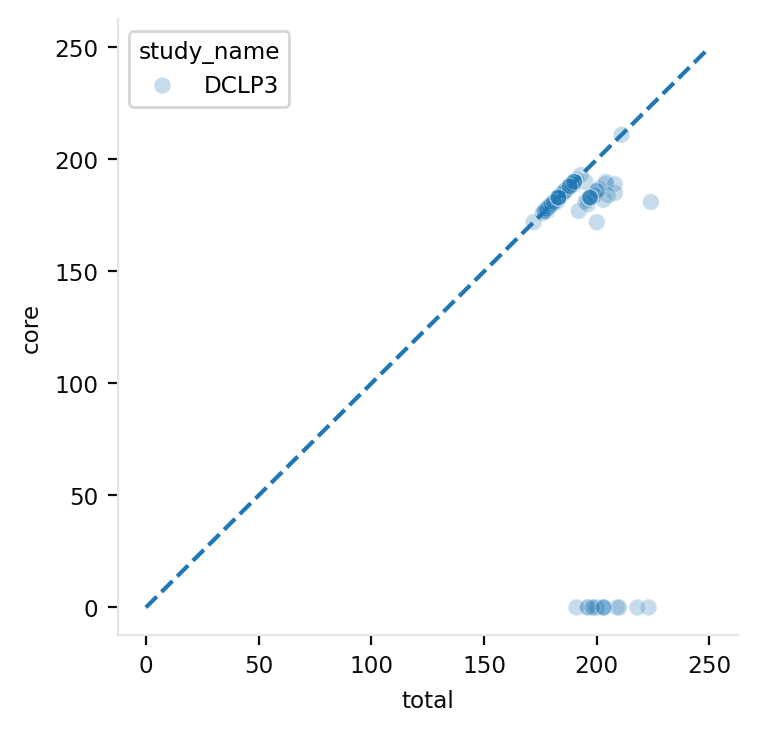

In [28]:
import seaborn as sns
f,ax = drawing.default_figure(4,4)
sns.scatterplot(df_coverage.query("study_name == 'DCLP3'"),x='total',y='core',hue='study_name',alpha=0.25)
ax.plot([0,250],[0,250],linestyle='--')

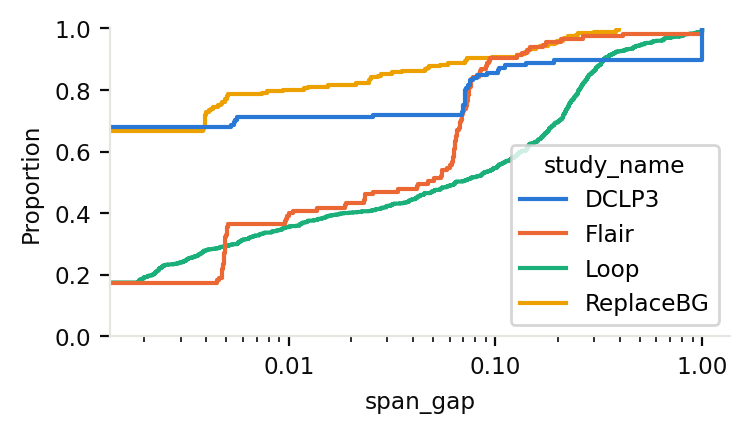

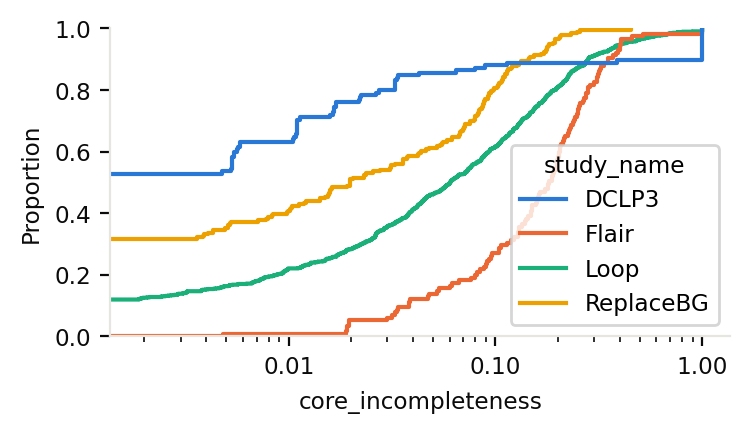

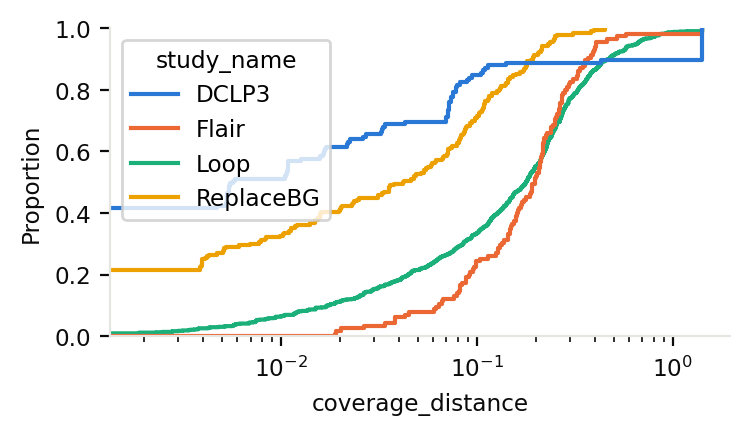

In [ ]:
import numpy as np
import seaborn as sns
from matplotlib.ticker import ScalarFormatter

f, ax = drawing.default_figure(4, 2)
sns.ecdfplot(df_coverage.assign(span_gap=1 - df_coverage.span_efficiency), x='span_gap', hue='study_name', ax=ax)
#sns.ecdfplot(df_coverage, x='span_efficiency', hue='study_name', ax=ax, complementary=True)
ax.set_xscale('log')
#ax.set_yscale('log')
ax.xaxis.set_major_formatter(ScalarFormatter())

f,ax = drawing.default_figure(4,2)
#sns.histplot(df_coverage, x='core_completeness', ax=ax, hue='study_name', stat='proportion', common_norm=False)
sns.ecdfplot(df_coverage.assign(core_incompleteness=1 - df_coverage.core_completeness), x='core_incompleteness', hue='study_name', ax=ax)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(ScalarFormatter())


In [16]:
df_coverage

NameError: name 'df_coverage' is not defined

In [ ]:

f,ax = drawing.default_figure(4,2)
sns.scatterplot(df_coverage,x='')
ax.set_xscale('log')
ax.xaxis.set_major_formatter(ScalarFormatter())


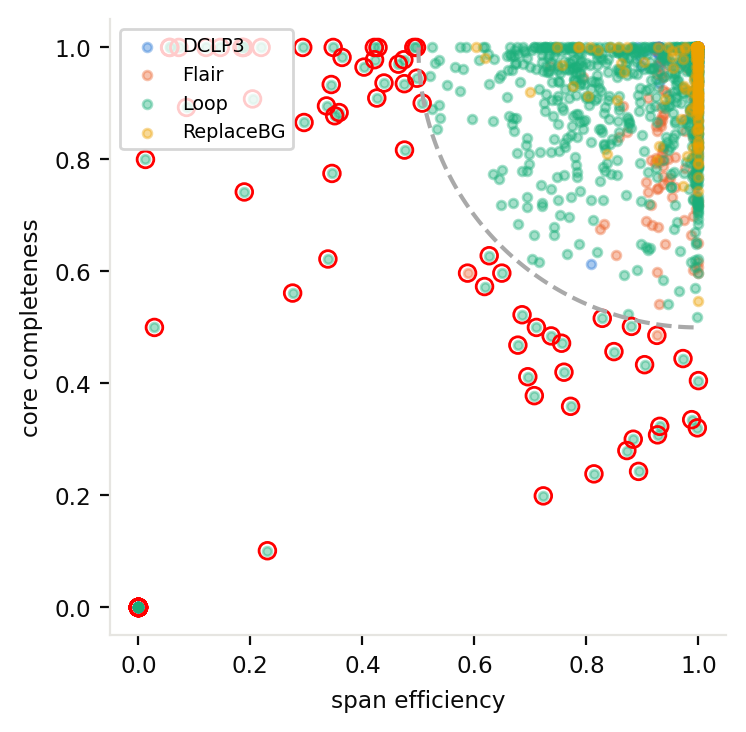

In [ ]:
df_coverage['coverage_distance'] = np.hypot(1 - df_coverage.span_efficiency, 1 - df_coverage.core_completeness)
DIST_THRESHOLD = 0.5
dist_outliers = df_coverage[df_coverage.coverage_distance>DIST_THRESHOLD]

f, ax = drawing.default_figure(4, 4)
for i, (study, df) in enumerate(df_coverage.groupby('study_name')):
    ax.scatter(df.span_efficiency, df.core_completeness, s=10, alpha=0.4, color=f'C{i}', label=study)

theta = np.linspace(0, np.pi / 2, 100)
distances = [np.sqrt(2*np.power(DIST_THRESHOLD,2))]#,np.sqrt(2*np.power(0.6,2)),np.sqrt(2*np.power(0.75,2))]
for r in [DIST_THRESHOLD]:
    ax.plot(1 - r * np.cos(theta), 1 - r * np.sin(theta), linestyle='--',color='darkgray')

sns.scatterplot(dist_outliers,edgecolor='red',facecolor='None',x='span_efficiency',y='core_completeness',linewidth=1)

ax.set(xlabel='span efficiency', ylabel='core completeness', 
       #xlim=(-0.05, 1.05), ylim=(-0.05, 1.05), 
       aspect='equal')
ax.legend(loc='upper left',fontsize='x-small')

display(dist_outliers.groupby('study_name').size())

## Trying out shit

In [70]:
df_cgm = store['cgm'].sort_values(['datetime'])


In [ ]:
df_cgm['gap_min'] = df_cgm.groupby(['study_name','patient_id'],observed=True).datetime.diff().dt.total_seconds()/60

In [73]:
df_cgm['day'] = df_cgm.datetime.dt.date

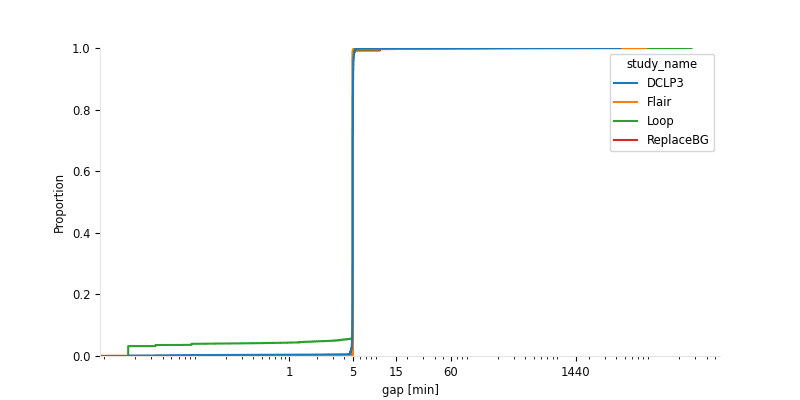

In [62]:
%matplotlib widget
from matplotlib.ticker import ScalarFormatter


df_sample = df_cgm.sample(int(1e6))

f, ax = drawing.default_figure()
sns.ecdfplot(df_sample, x='gap_min', hue='study_name', ax=ax,hue_order=sorted(df_sample.study_name.unique()))
ax.set(xscale='log', xlabel='gap [min]', xticks=[1, 5, 15, 60, 1440])
ax.xaxis.set_major_formatter(ScalarFormatter())

Text(0.5, 1.0, 'Share of Short vs. Long CGM Gaps')

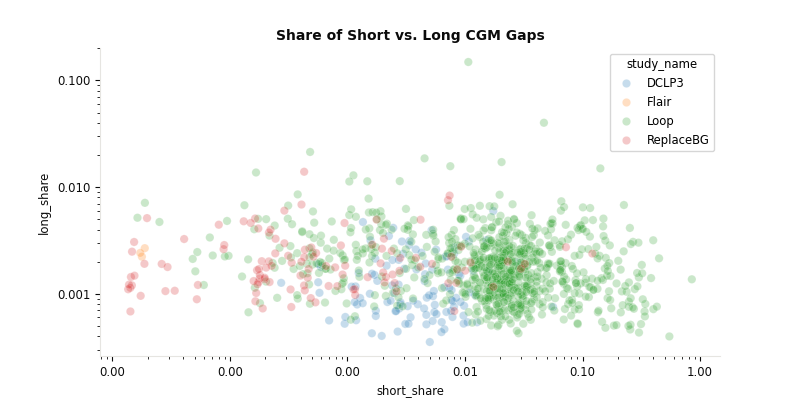

In [112]:
df_cgm['short'] = df_cgm.gap_min < 4
df_cgm['long'] = df_cgm.gap_min > 20

df_cadence = df_cgm.groupby(KEYS, observed=True).agg(
    median_gap=('gap_min', 'median'),
    short_share=('short', 'mean'),
    long_share=('long', 'mean'),
)

f,ax = drawing.default_figure()
sns.scatterplot(df_cadence,x='short_share',y='long_share',alpha=.25, hue='study_name', hue_order=sorted(df_cgm.study_name.unique()))
ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_major_formatter(ScalarFormatter())

ax.set_title('Share of Short vs. Long CGM Gaps')


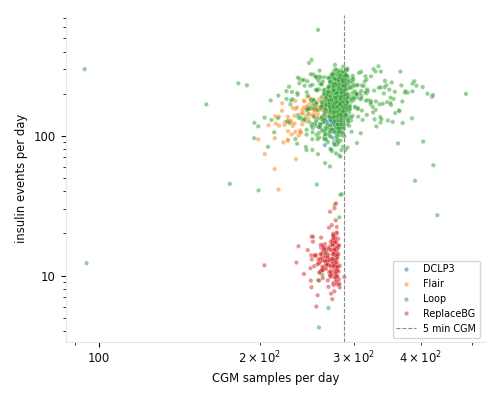

In [122]:
KEYS = ['study_name', 'patient_id']

def samples_per_day(df):
    daily = df.groupby(KEYS + [df.datetime.dt.normalize().rename('date')], observed=True).size()
    return daily.groupby(KEYS, observed=True).mean()

basal = samples_per_day(store['basal'])
bolus = samples_per_day(store['bolus'])
df_rates = pd.DataFrame({
    'cgm_per_day': samples_per_day(store['cgm']),
    'insulin_per_day': basal.add(bolus, fill_value=0),
})

f, ax = drawing.default_figure(5, 4)
sns.scatterplot(df_rates, x='cgm_per_day', y='insulin_per_day', hue='study_name', s=10, ax=ax,
                hue_order=sorted(df_rates.index.unique('study_name')),alpha=0.5)
ax.axvline(288, color=MUTED, linestyle='--', linewidth=0.8, label='5 min CGM')
ax.set(xscale='log', yscale='log', xlabel='CGM samples per day', ylabel='insulin events per day')
ax.legend(fontsize='x-small')

ax.xaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_major_formatter(ScalarFormatter())
plt.tight_layout()

## CGM
Stimmt die Messfrequenz: Anteil der werte

In [131]:
sample = df_cgm.head(1000)

In [ ]:
sample = sample.assign(gap_min_rnd = sample.gap_min.round(1))
hour_gaps = sample.gap_min.mod(60)
cadence = (sample.gap_min_rnd==5) | (sample.gap_min_rnd==15)
cadence.groupby([sample.study_name, sample.patient_id], observed=True).mean()

study_name  patient_id
ReplaceBG   10            0.928571
            129           0.928571
            135           0.928571
            138           0.923077
            141           0.928571
                            ...   
            174           0.928571
            220           0.928571
            229           0.928571
            243           0.928571
            285           0.928571
Name: gap_min, Length: 72, dtype: float64

/var/folders/m4/5d02b2xs0l52lbxzbk0t3vym0000gp/T/ipykernel_75463/3145821838.py:11: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  ax.scatter(df_p[shift_like].datetime,df_p[shift_like].cgm,color='red',zorder=2)
/var/folders/m4/5d02b2xs0l52lbxzbk0t3vym0000gp/T/ipykernel_75463/3145821838.py:11: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  ax.scatter(df_p[shift_like].datetime,df_p[shift_like].cgm,color='red',zorder=2)


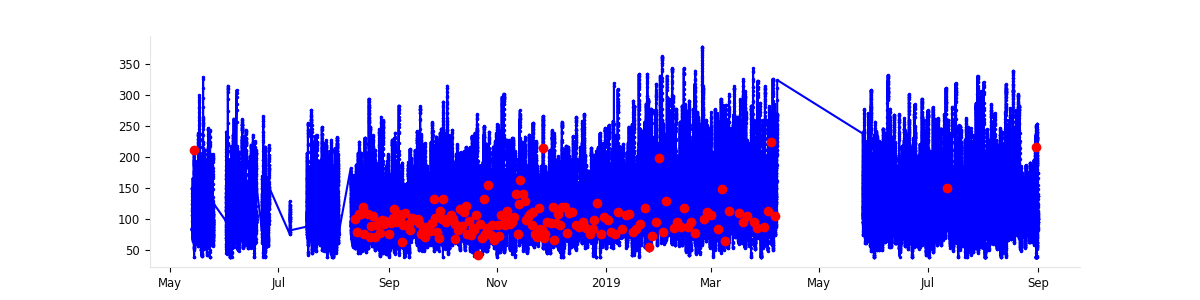

In [210]:
gaps = df_cgm.gap_min.round()
cadence = 5   # use each patient's median gap if devices differ
shift_like = (gaps > 60) & ((gaps - cadence).mod(60) == 0)
shift_like.groupby([df_cgm.study_name, df_cgm.patient_id], observed=True).sum().sort_values()

%matplotlib widget
df_p = df_cgm.query("(patient_id == 510) & (study_name == 'Loop')")
f,ax = drawing.default_figure(12,3)

ax.plot(df_p.datetime,df_p.cgm,color='blue',marker='.',markersize=3)
ax.scatter(df_p[shift_like].datetime,df_p[shift_like].cgm,color='red',zorder=2)

import matplotlib.dates as mdates
#locator = mdates.AutoDateLocator()
locator = mdates.AutoDateLocator(minticks=6, maxticks=12)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))


/var/folders/m4/5d02b2xs0l52lbxzbk0t3vym0000gp/T/ipykernel_75463/571387105.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  hours_between_events = df_p[shift_like].datetime.diff().dt.total_seconds()/3600
/var/folders/m4/5d02b2xs0l52lbxzbk0t3vym0000gp/T/ipykernel_75463/571387105.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  time_of_day_event = df_p[shift_like].datetime.dt.hour
/var/folders/m4/5d02b2xs0l52lbxzbk0t3vym0000gp/T/ipykernel_75463/571387105.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  gap_duration = df_p[shift_like].gap_min/60


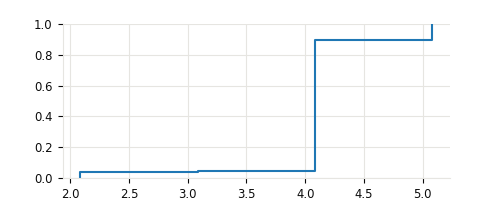

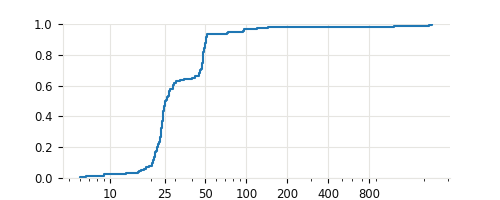

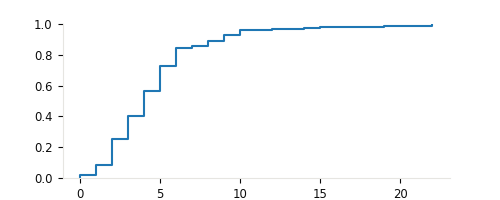

In [206]:
hours_between_events = df_p[shift_like].datetime.diff().dt.total_seconds()/3600
time_of_day_event = df_p[shift_like].datetime.dt.hour
gap_duration = df_p[shift_like].gap_min/60
#duration
f,ax = drawing.default_figure(5,2)
ax.ecdf(gap_duration)
ax.grid('on')
#ax.set_xscale('log')
#ax.set_xticks(np.arange(1,10,1))
#ax.xaxis.set_major_formatter(ScalarFormatter())

#hours between events
f,ax = drawing.default_figure(5,2)
ax.ecdf(hours_between_events.dropna())
ax.grid('on')
ax.set_xscale('log')
ax.set_xticks([10,25,50,100,200,400,800])
ax.xaxis.set_major_formatter(ScalarFormatter())

#time of day
f,ax = drawing.default_figure(5,2)
ax.ecdf(time_of_day_event)
